In [193]:
import pickle
from collections import defaultdict
from tqdm.auto import tqdm, trange

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
def yn_to_tensor(X_s, df, n_support=100):
    X_y_yn = -np.ones((len(X_s), n_support, 2))
    
    for _, row in df.iterrows():
        X, y, yes, no = row['set'], row['target'], row['yes'], row['no']
        X_i = X_s.index(X)

        X_y_yn[X_i, y-1, :] = [yes, yes+no]

    return np.array(X_y_yn)



X_s  = sorted(set(df_bp['set']))
obs_y = yn_to_tensor(X_s, df_bp, n_support=100)

df_bp = pd.read_csv('./data/bp_number_game/human-data.txt', sep='\t')

In [79]:
# agg_pred_8b = agg_pred
# agg_pred_70b = agg_pred

In [78]:
## llm_fname = './out/together_results_FULL.pk'
llm_fname = './out/results_llama-3-1-70b.pk'

all_results, all_queries = pickle.load(open(llm_fname, 'rb'))

agg_res = defaultdict(lambda: np.zeros((100, 2)))
yn_keys = {'Yes': 1, 'No': 0}

for res, (messages, X, y, yn) in zip(all_results, all_queries):
    yn_lp = res['completion']['prompt'][0]['logprobs']['token_logprobs'][-1]
    yn_01 = yn_keys[yn]
    agg_res[X][y-1, yn_01] = yn_lp


agg_pred = {}

for X, y_lp in agg_res.items():
    y_pr = np.exp(y_lp)
    y_pr = y_pr[:, 1] / y_pr.sum(axis=1)
    agg_pred[X] = y_pr

In [9]:
rule_concepts = [
    # Powers of n
    ('powers of 2', [2, 4, 8, 16, 32, 64]),
    ('powers of 3', [3, 9, 27, 81]),
    ('powers of 4', [4, 16, 64]),
    ('powers of 5', [5, 25]),
    ('powers of 6', [6, 36]),
    ('powers of 7', [7, 49]),
    ('powers of 8', [8, 64]),
    ('powers of 9', [9, 81]),
    ('powers of 10', [10, 100]),

    # Multiples of n
    ('multiples of 3', [i for i in range(1, 101) if i % 3 == 0]),
    ('multiples of 4', [i for i in range(1, 101) if i % 4 == 0]),
    ('multiples of 5', [i for i in range(1, 101) if i % 5 == 0]),
    ('multiples of 6', [i for i in range(1, 101) if i % 6 == 0]),
    ('multiples of 7', [i for i in range(1, 101) if i % 7 == 0]),
    ('multiples of 8', [i for i in range(1, 101) if i % 8 == 0]),
    ('multiples of 9', [i for i in range(1, 101) if i % 9 == 0]),
    ('multiples of 10', [i for i in range(1, 101) if i % 10 == 0]),
    ('multiples of 11', [i for i in range(1, 101) if i % 11 == 0]),
    ('multiples of 12', [i for i in range(1, 101) if i % 12 == 0]),

    # Ends with digit n
    # ('ends with digit 0', [i for i in range(1, 101) if i % 10 == 0]),
    ('ends with digit 1', [i for i in range(1, 101) if i % 10 == 1]),
    ('ends with digit 2', [i for i in range(1, 101) if i % 10 == 2]),
    ('ends with digit 3', [i for i in range(1, 101) if i % 10 == 3]),
    ('ends with digit 4', [i for i in range(1, 101) if i % 10 == 4]),
    ('ends with digit 5', [i for i in range(1, 101) if i % 10 == 5]),
    ('ends with digit 6', [i for i in range(1, 101) if i % 10 == 6]),
    ('ends with digit 7', [i for i in range(1, 101) if i % 10 == 7]),
    ('ends with digit 8', [i for i in range(1, 101) if i % 10 == 8]),
    ('ends with digit 9', [i for i in range(1, 101) if i % 10 == 9]),

    # Contains digit n
    # ('contains digit 0', [i for i in range(1, 101) if '0' in str(i)]),
    ('contains digit 1', [i for i in range(1, 101) if '1' in str(i)]),
    ('contains digit 2', [i for i in range(1, 101) if '2' in str(i)]),
    ('contains digit 3', [i for i in range(1, 101) if '3' in str(i)]),
    ('contains digit 4', [i for i in range(1, 101) if '4' in str(i)]),
    ('contains digit 5', [i for i in range(1, 101) if '5' in str(i)]),
    ('contains digit 6', [i for i in range(1, 101) if '6' in str(i)]),
    ('contains digit 7', [i for i in range(1, 101) if '7' in str(i)]),
    ('contains digit 8', [i for i in range(1, 101) if '8' in str(i)]),
    ('contains digit 9', [i for i in range(1, 101) if '9' in str(i)]),

    # is Prime
    ('prime', [1, 2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]),
    ### [i for i in range(1, 101) if not any([i == (j1 * j2) for j1 in range(1, i) for j2 in range(1, i)])],

    # is even/odd
    ('even', [i for i in range(1, 101) if i % 2 == 0]),
    ('odd', [i for i in range(1, 101) if i % 2 == 1]),
    # squares/cubes
    ('squares x^2', [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]),
    ('cubes x^3', [1, 8, 27, 64]),
]

rule_concept_names = [name for name, _ in rule_concepts]

In [55]:
def color_concept(c_idx):
    concept_name, C = rule_concepts[c_idx]
    colors = [('orange' if c in C else 'deepskyblue') for c in range(1, 101)]
    return concept_name, C, colors

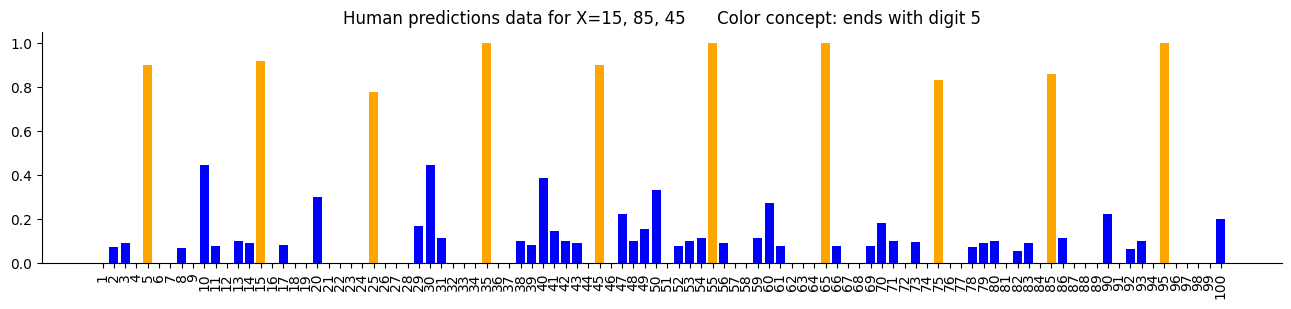

In [26]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = 25  # 21/24   # 20   3 
c_idx = 23        # 26   10

y_yes, y_total = obs_y[..., 0], obs_y[..., 1]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_yes[i] / y_total[i], color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'Human predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

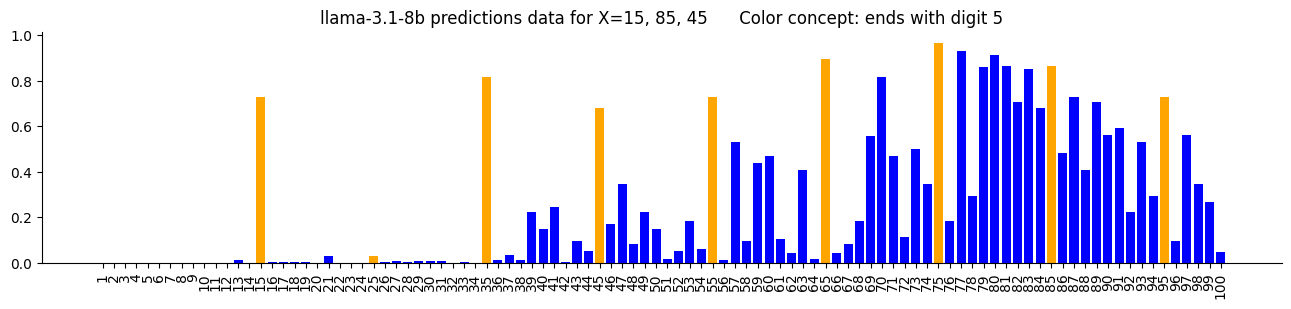

In [46]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = 25  # 21/24   # 20   3 
c_idx = 23        # 26   10

### i = 47
### c_idx = 29


y_preds = agg_pred[X_s[i]]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3.1-8b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

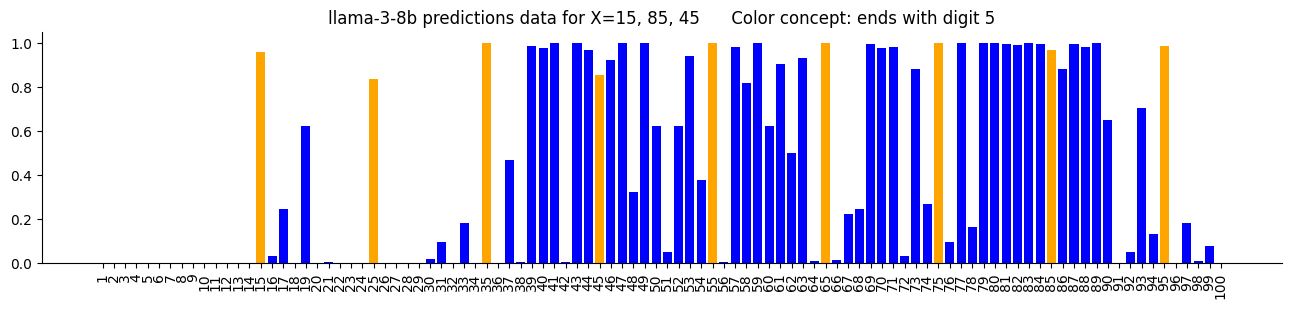

In [37]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = 25  # 21/24   # 20   3 
c_idx = 23        # 26   10

### i = 47
### c_idx = 29


y_preds = agg_pred[X_s[i]]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3-8b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

In [30]:
X_s.index('22,62,26,82')

47

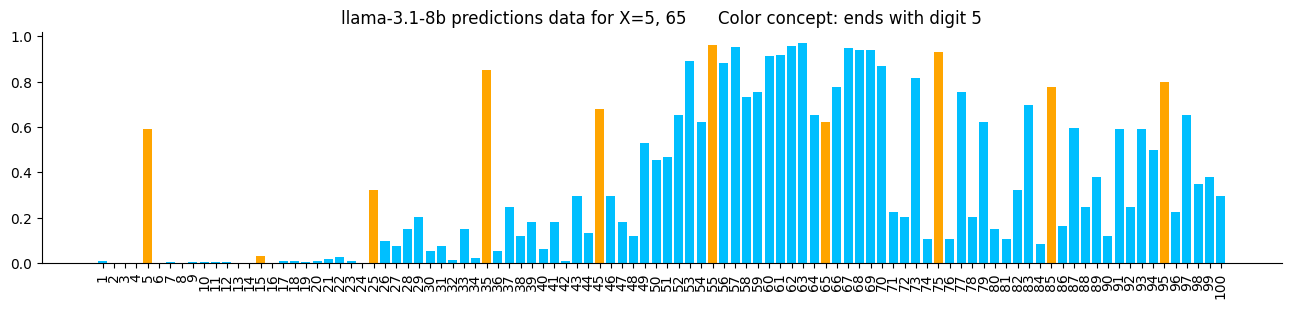

In [76]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = X_s.index('5,65')
# i = X_s.index('55,60,25,100')
c_idx = 23 #23

### i = 47
### c_idx = 29


y_preds = agg_pred[X_s[i]]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3.1-8b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

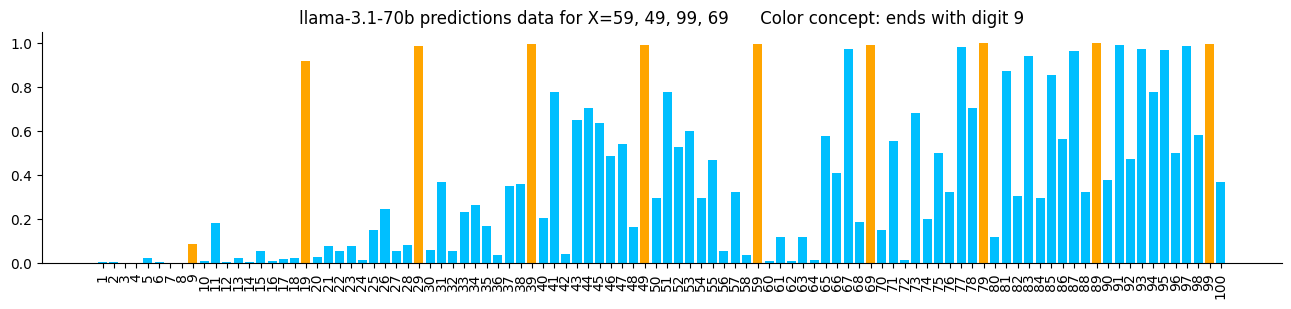

In [85]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
# i = X_s.index('5,65')
i = X_s.index('59,49,99,69')
c_idx = 27 #23

### i = 47
### c_idx = 29


y_preds = agg_pred[X_s[i]]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3.1-70b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

In [41]:
res.keys()

dict_keys(['choice', 'completion', 'messages', 'messages_raw', 'messages_args', 'model_args'])

In [44]:
[res['messages_raw'][0] for res, (messages, X, y, yn) in zip(all_results, all_queries) if X == X_s[i]]

[{'role': 'user',
  'content': 'First, you will see a set of integer numbers in the range [1, 100] which are randomly sampled from a hidden number concept. Note that ordering in this set does not matter.\n\nThen, you will answer yes/no whether another number belongs to the same concept. Respond only with a single word, Yes or No.\n\nHere is a set of numbers sampled from a concept: {15, 85, 45}\n\nNow, does the following query number belong to the same concept as {15, 85, 45}?\nQuery number: 1'},
 {'role': 'user',
  'content': 'First, you will see a set of integer numbers in the range [1, 100] which are randomly sampled from a hidden number concept. Note that ordering in this set does not matter.\n\nThen, you will answer yes/no whether another number belongs to the same concept. Respond only with a single word, Yes or No.\n\nHere is a set of numbers sampled from a concept: {15, 85, 45}\n\nNow, does the following query number belong to the same concept as {15, 85, 45}?\nQuery number: 1'}

In [ ]:
import numpyro
from numpyro.infer import MCMC, NUTS, SVI
import numpyro.distributions as dist

import infer

In [276]:
mcmc = pickle.load(open('./out/mcmc_llama8b.pk', 'rb'))
samples = mcmc.get_samples()

Text(0.5, 0, 'Mixture Param.')

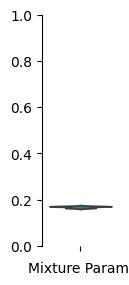

In [99]:
plt.rcParams['figure.figsize'] = (1, 3)

sns.violinplot(samples['p_mix'], inner=None, cut=0);
sns.despine(bottom=True);
plt.ylim(0, 1)

plt.xlabel('Mixture Param.')

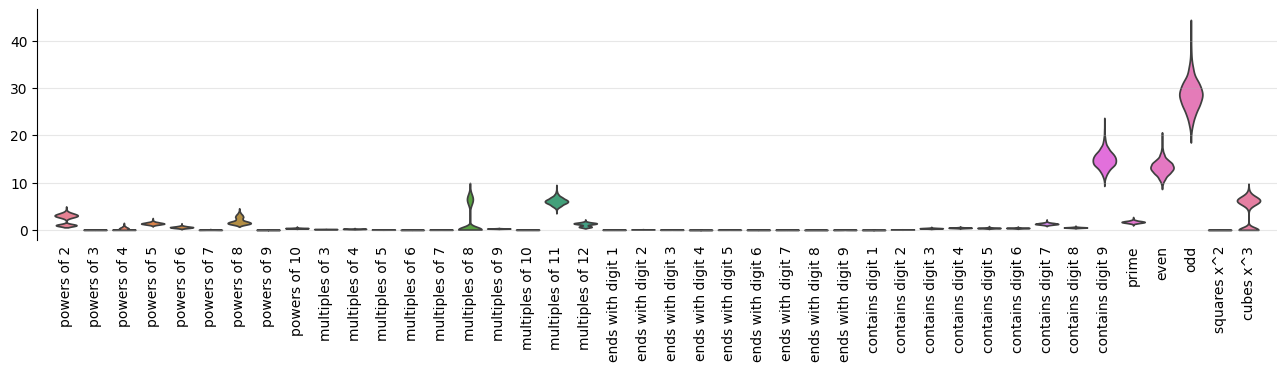

In [89]:
plt.rcParams['figure.figsize'] = (16, 3)


n_rules = 42

###sns.violinplot(samples['p_rules'][:, :n_rules][:, cogsci16_orders], inner=None, cut=0)
###plt.xticks(range(n_rules), np.array(rule_concept_names[:n_rules])[cogsci16_orders], rotation=90);

sns.violinplot(samples['p_rules'][:, :n_rules], inner=None, cut=0)         #### WITHOUT COGSCI ORDERING
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90);

# plt.hlines(0, 0, 42)
plt.grid(alpha=.3, axis='y')
plt.tick_params(axis='x', which='both', length=0)

# plt.ylim(-1, 5)
plt.xlim(-1, n_rules)

sns.despine(bottom=True);

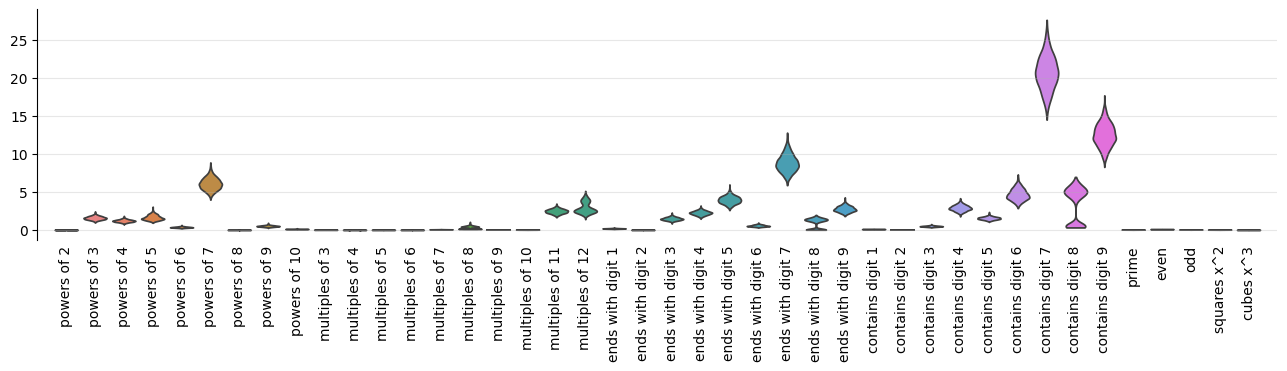

In [277]:
plt.rcParams['figure.figsize'] = (16, 3)


n_rules = 42

###sns.violinplot(samples['p_rules'][:, :n_rules][:, cogsci16_orders], inner=None, cut=0)
###plt.xticks(range(n_rules), np.array(rule_concept_names[:n_rules])[cogsci16_orders], rotation=90);

sns.violinplot(samples['p_rules'][:, :n_rules], inner=None, cut=0)         #### WITHOUT COGSCI ORDERING
plt.xticks(range(n_rules), rule_concept_names[:n_rules], rotation=90);

# plt.hlines(0, 0, 42)
plt.grid(alpha=.3, axis='y')
plt.tick_params(axis='x', which='both', length=0)

# plt.ylim(-1, 5)
plt.xlim(-1, n_rules)

sns.despine(bottom=True);

In [278]:
agg_pred.keys()

dict_keys(['1', '1,8,27', '10', '10,3', '10,50,100', '10,55,58', '10,66,29', '10,74,22', '10,80', '100', '100,1,16', '11', '11,26,74,2', '11,41,38,92', '12', '12,84,8', '13', '13,91', '14', '14,47', '14,98,91', '15', '15,11', '15,17,21,5', '15,39,35', '15,85,45', '15,93', '16', '16,26,96', '16,32,2,8', '16,54', '16,8', '16,82,28', '17', '17,11,65,53', '17,50,5,82', '18', '18,45,72', '18,8,72,98', '19,73', '2', '2,47', '2,8', '20,32,92', '20,8,84,100', '21,71', '22', '22,62,26,82', '22,96', '23', '23,35,95,83', '23,62,98', '23,80', '24,35', '25', '25,17', '25,82', '26', '26,2', '27,37,67', '28,13', '28,2', '28,98', '29,62,98', '29,77,37,17', '29,9,3,31', '3', '3,31', '3,33,99', '3,63', '3,7', '3,81', '3,87', '30', '31', '31,19,49,100', '31,3,1', '31,3,1,15', '32,4,16', '33', '33,17,5,9', '33,3', '33,3,65', '33,5,19', '33,9', '34,26', '34,86,30,94', '35', '36', '36,45,54,81', '37,57', '38,18,3', '39', '39,60,12,45', '4', '4,16,12', '4,64,25,81', '4,66,78,96', '42,35,21,84', '42,62', '43'

In [280]:
np.array(list(agg_pred.values())).shape

(255, 100)

In [290]:
obs_py.shape

(255, 100)

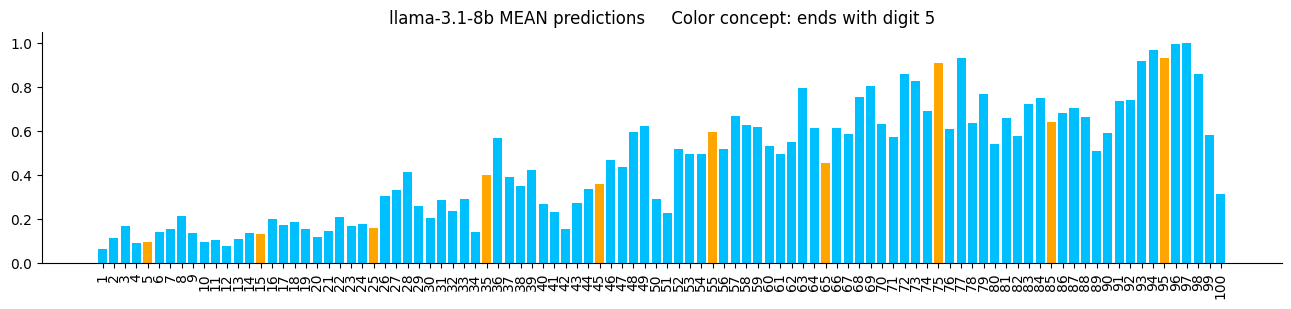

In [297]:
plt.rcParams['figure.figsize'] = (16, 3)

# c_idx = 16 #23
y_preds = obs_py.mean(axis=0)    #np.array(list(agg_pred.values())).mean(axis=0)
y_preds /= y_preds.max()

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3.1-8b MEAN predictions     Color concept: {concept_name}');
sns.despine();

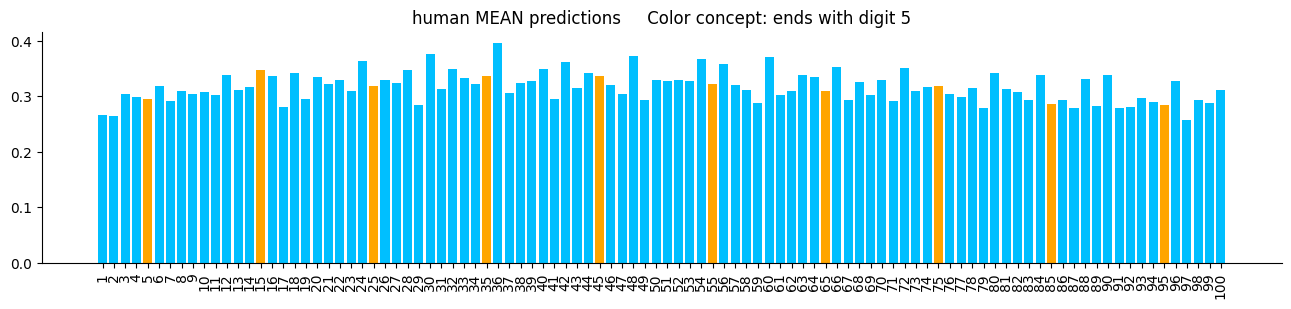

In [288]:
plt.rcParams['figure.figsize'] = (16, 3)

c_idx = 23        # 26   10

y_yes, y_total = obs_y[..., 0], obs_y[..., 1]
y_pred = (y_yes / y_total).mean(axis=0)

# y_preds = np.array(list(agg_pred.values())).mean(axis=0)

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_pred, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'human MEAN predictions     Color concept: {concept_name}');
sns.despine();

# TODO: Make predictions based on Bayesian model

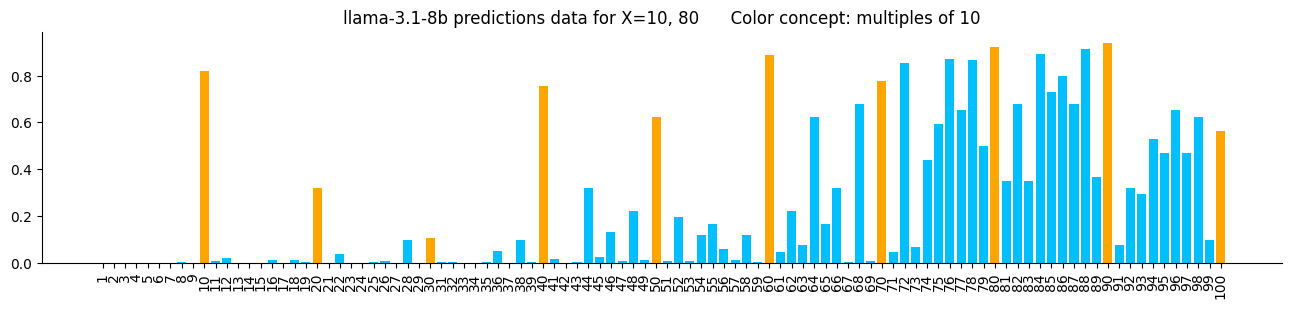

In [264]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = X_s.index(run_number.CONCEPT_SETS[0])
# i = X_s.index('5')
# i = X_s.index('55,60,25,100')
c_idx = 16 #23

### i = 47
### c_idx = 29


y_preds = agg_pred[X_s[i]]

concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), y_preds, color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'llama-3.1-8b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

In [111]:
mcmc = pickle.load(open('./out/mcmc-2var_llama.pk', 'rb'))
samples = mcmc.get_samples()

In [91]:
from run_number_llama import *

In [139]:
import scipy

In [214]:
df_bp = pd.read_csv('./data/bp_number_game/human-data.txt', sep='\t')
X_s  = sorted(set(df_bp['set']))
obs_X = X_to_tensor(X_s)

# Load LLM prediction data for  p*(y | X)
agg_pred = load_llm_data('./out/results_llama-3-1-8b.pk')
obs_py = preds_to_array(agg_pred, X_s)

# Likelihoods  p(X | h)  for each h
h_likelihoods, y_predictives = get_likelihoods_predictives()

X_ = obs_X[..., None]
X_likelihoods = dist.Categorical(probs=h_likelihoods).mask(X_ != -1).log_prob(X_).sum(axis=-2)          ##### shape: (n_hypotheses, n_data)

In [93]:
samples.keys()

dict_keys(['p_mix', 'p_rules'])

In [104]:
X_likelihoods.shape

(255, 5092)

In [105]:
samples['p_rules'].T.shape

(42, 6000)

In [110]:
samples['p_rules'].shape[0]

6000

In [218]:
def get_post_predict(samples, y_predictives, X_likelihoods):
    log_prior      = jnp.log(samples['h_prior']).T
    log_posterior  = log_prior[None, ...] + X_likelihoods[..., None]
    log_posterior -= jax.nn.logsumexp(log_posterior, axis=1, keepdims=True)    # normalize over H

    # Compute predictive by model averaging over H
    post_predictive = jnp.einsum('nhz, hzs -> zns', jnp.exp(log_posterior), y_predictives[:, None, :])
    # post_predictive /= log_prior.shape[1]
    return post_predictive

post_predict = get_post_predict(samples, y_predictives, X_likelihoods)

In [219]:
X_likelihoods.shape

(255, 5092)

In [221]:
import run_number

In [228]:
run_number.concept_set_to_likelihood(list(range(1,101)), epsilon=0)

Array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01], dtype=float32, weak_type=True)

In [217]:
post_predict.shape

(300, 255, 100)

In [119]:
predicts = post_predict.sum(axis=0) / post_predict.shape[0]

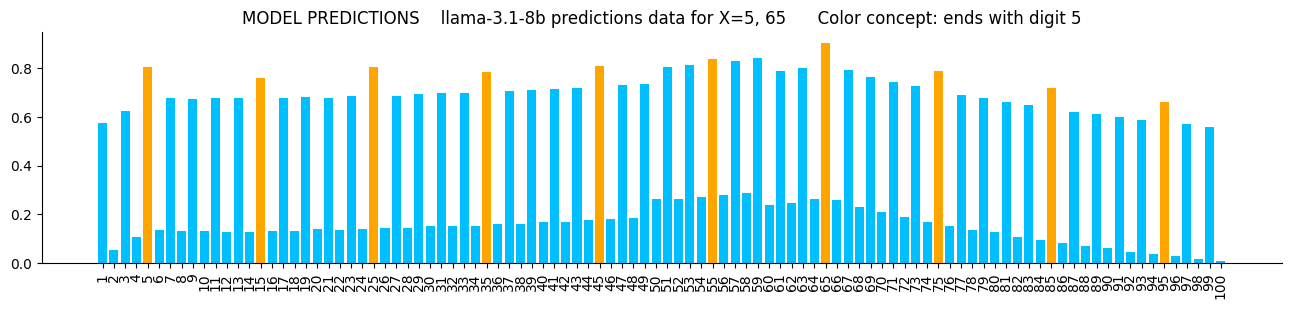

In [121]:
plt.rcParams['figure.figsize'] = (16, 3)

# `i` is the specific data example we're going to look at, with X = [48, 78, 38, 98]
i = X_s.index('5,65')
# i = X_s.index('55,60,25,100')
c_idx = 23 #23

### i = 47
### c_idx = 29



concept_name, _, color = color_concept(c_idx)
plt.bar(range(100), predicts[i], color=color)
plt.xticks(range(100), range(1, 101), rotation=90);

plt.title(f'MODEL PREDICTIONS    llama-3.1-8b predictions data for X={X_s[i].replace(",", ", ")}      Color concept: {concept_name}');
sns.despine();

In [122]:
predicts.shape

(255, 100)

In [124]:
obs_y[0, 0, :]

array([5., 9.])

In [204]:
obs_py = preds_to_array(agg_pred, X_s)

R squared: 0.12898527109396515


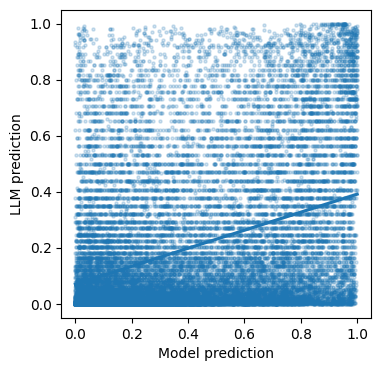

In [205]:
plt.rcParams['figure.figsize'] = (4, 4)

llm_predicts = obs_py #obs_y[:, :, 0] / obs_y[:, :, 1]

x = predicts.flatten()
y = llm_predicts.flatten()

sns.regplot(x=x, y=y, scatter_kws={'alpha': .2, 's': 5})
plt.xlabel('Model prediction')
plt.ylabel('LLM prediction')

r_corr = scipy.stats.pearsonr(x, y)  #, *, alternative='two-sided', method=None)
print(f'R squared: {r_corr.statistic ** 2}')

In [189]:
def round_to_05(x):
    # round down to nearest .05
    return np.floor(20*x) * 5/100

In [206]:
human_predicts = obs_y[:, :, 0] / obs_y[:, :, 1]

rows = []

for n in trange(255):
    for s in range(100):
        llm_p   = llm_predicts[n, s]
        model_p = predicts[n, s]
        human_p = human_predicts[n, s]
        rows.append({
            'n': n,
            's': s,
            'human_p': human_p,
            'llm_p': llm_p,
            'model_p': model_p,
            'bucket': f'{round_to_05(model_p):.2f}',
        })

df_p = pd.DataFrame(rows)

  0%|          | 0/255 [00:00<?, ?it/s]

In [210]:
bucket_means = df_p[['human_p', 'model_p', 'llm_p', 'bucket']].groupby('bucket').aggregate('mean').reset_index(drop=True)

r_corr = scipy.stats.pearsonr(bucket_means['llm_p'], bucket_means['model_p'])
print(f'LLM R squared: {r_corr.statistic ** 2}')
r_corr = scipy.stats.pearsonr(bucket_means['human_p'], bucket_means['model_p'])
print(f'Human R squared: {r_corr.statistic ** 2}')

bucket_means

LLM R squared: 0.8665922114753016
Human R squared: 0.967060869313709


,human_p,model_p,llm_p
0,0.128092,0.022503,0.103909
1,0.162963,0.074369,0.127127
2,0.195574,0.124681,0.126541
3,0.230009,0.174366,0.128476
4,0.257312,0.223712,0.140408
5,0.280683,0.274428,0.141207
6,0.287917,0.3244,0.140219
7,0.304928,0.375215,0.157859
8,0.309632,0.424596,0.164246
9,0.329911,0.47365,0.188106


R squared: 0.1282312595541622


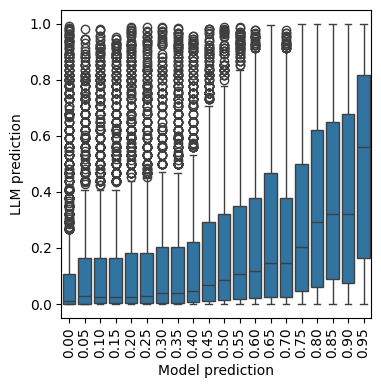

In [208]:
plt.rcParams['figure.figsize'] = (4, 4)

human_predicts = obs_py  #obs_y[:, :, 0] / obs_y[:, :, 1]

x = predicts.flatten()
x = round_to_05(x)
xs = [f'{x_:.2f}' for x_ in x]

y = human_predicts.flatten()

sns.boxplot(x=xs, y=y, order=sorted(set(xs)))
plt.xlabel('Model prediction')
plt.ylabel('LLM prediction')
plt.xticks(rotation=90)


r_corr = scipy.stats.pearsonr(x, y)  #, *, alternative='two-sided', method=None)
print(f'R squared: {r_corr.statistic ** 2}')

PearsonRResult(statistic=0.5345187234268175, pvalue=0.0)